<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/09_Modified_Model_Training_Diagnosis_Driven.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09 — Diagnosis-Driven Modified SegFormer-B2 Training

This notebook starts **Phase 2** of the project after the fixed-model diagnosis in Notebooks 01–08.

The logic is:

1. Find **which classes change most** under each adverse condition.
2. Prefer the **matched ACDC normal/adverse analysis** over the broad Cityscapes→ACDC difference when deciding what to modify.
3. Use **bootstrap stability and class support** so an unstable rare-class result is not over-emphasized.
4. Modify SegFormer-B2 based on those findings.
5. Train only on **ACDC train** data.


### Modification used here
- **Lightweight residual channel-attention refinement head** added to SegFormer-B2's decoder classifier.
- **Condition-specific vulnerability-aware loss** derived from train-only matched IoU change + bootstrap direction stability + both-side class support.



## GPU Setup




In [ ]:
# Cell 1 — Install/import dependencies
!pip -q install -U transformers accelerate

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, math, random, shutil, zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from transformers import AutoImageProcessor, SegformerForSemanticSegmentation

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        'GPU is required for Notebook 09. In Colab go to Runtime > Change runtime type > '
        'Hardware accelerator > GPU, then reconnect.'
    )

DEVICE = torch.device('cuda')
GPU_NAME = torch.cuda.get_device_name(0)
print('Using device:', DEVICE)
print('GPU:', GPU_NAME)
print('CUDA version:', torch.version.cuda)

torch.backends.cudnn.benchmark = True


Mounted at /content/drive
PyTorch: 2.14.1+cu130
CUDA available: True
Using device: cuda
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
# Cell 2 — Project paths and constants
PROJECT_ROOT = Path('/content/drive/MyDrive/CV_Project')
DATASETS_DIR = PROJECT_ROOT / 'datasets'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
LOGS_DIR = PROJECT_ROOT / 'logs'

MATCHED_RESULTS_DIR = RESULTS_DIR / 'matched_acdc'
CACHE_DIR = MATCHED_RESULTS_DIR / 'per_pair_confusions_masked_v2'

MOD_RESULTS_DIR = RESULTS_DIR / 'model_modification'
MOD_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUT_DIR = MODELS_DIR / 'vulnerability_aware_segformer_b2'
MODEL_OUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_LOG_DIR = LOGS_DIR / 'vulnerability_aware_segformer_b2'
TRAIN_LOG_DIR.mkdir(parents=True, exist_ok=True)

ACDC_RGB_ZIP = DATASETS_DIR / 'acdc' / 'rgb_anon.zip'
ACDC_GT_ZIP = DATASETS_DIR / 'archives' / 'gt_trainval.zip'

BASE_CHECKPOINT = 'nvidia/segformer-b2-finetuned-cityscapes-1024-1024'
CONDITIONS = ['fog', 'rain', 'snow', 'night']
NUM_CLASSES = 19
IGNORE_INDEX = 255

CLASS_NAMES = [
    'road', 'sidewalk', 'building', 'wall', 'fence', 'pole',
    'traffic light', 'traffic sign', 'vegetation', 'terrain', 'sky',
    'person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle'
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
CONDITION_TO_ID = {name: i for i, name in enumerate(CONDITIONS)}

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print('Project root:', PROJECT_ROOT)
print('Train-only diagnostic cache:', CACHE_DIR)
print('Modified model output:', MODEL_OUT_DIR)

Project root: /content/drive/MyDrive/CV_Project
Train-only diagnostic cache: /content/drive/MyDrive/CV_Project/results/matched_acdc/per_pair_confusions_masked_v2
Modified model output: /content/drive/MyDrive/CV_Project/models/vulnerability_aware_segformer_b2


## Part A — Rebuild the diagnosis using **ACDC train correspondences only**



In [ ]:
# Cell 3 — Load the 800 train-only matched scene caches (200 per condition)
assert CACHE_DIR.exists(), (
    f'Missing {CACHE_DIR}. Run the final Notebook 06 first so '
    'per_pair_confusions_masked_v2 is available.'
)

pair_records = []
for path in sorted(CACHE_DIR.glob('*.npz')):
    z = np.load(path, allow_pickle=False)
    reference_split = str(z['reference_split'])
    if reference_split != 'train_ref':
        continue

    pair_records.append({
        'path': path,
        'condition': str(z['condition']),
        'scene_key': str(z['scene_key']),
        'ref_confusion': z['ref_confusion'].astype(np.int64),
        'adverse_confusion': z['adverse_confusion'].astype(np.int64),
        'ref_presence': z['ref_presence'].astype(bool),
        'adverse_presence': z['adverse_presence'].astype(bool),
    })

print('Train matched pairs:', len(pair_records))
counts = pd.Series([r['condition'] for r in pair_records]).value_counts().reindex(CONDITIONS)
display(counts.rename('train_pairs').to_frame())

assert len(pair_records) == 800, 'Expected 800 train_ref correspondences (200 × 4).'
assert (counts.values == 200).all(), 'Expected 200 train pairs per condition.'
print('✓ Train-only matched diagnosis set verified.')

Train matched pairs: 800


,train_pairs
fog,200
rain,200
snow,200
night,200


✓ Train-only matched diagnosis set verified.


In [ ]:
# Cell 4 — Metric helpers

def iou_from_confusion(cm):
    cm = cm.astype(np.float64)
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    union = tp + fp + fn
    iou = np.full(NUM_CLASSES, np.nan, dtype=np.float64)
    valid = union > 0
    iou[valid] = tp[valid] / union[valid]
    return iou


def aggregate_records(records):
    ref_cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    adv_cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    ref_presence = np.zeros((len(records), NUM_CLASSES), dtype=bool)
    adv_presence = np.zeros((len(records), NUM_CLASSES), dtype=bool)

    for i, r in enumerate(records):
        ref_cm += r['ref_confusion']
        adv_cm += r['adverse_confusion']
        ref_presence[i] = r['ref_presence']
        adv_presence[i] = r['adverse_presence']

    ref_iou = iou_from_confusion(ref_cm)
    adv_iou = iou_from_confusion(adv_cm)
    change = ref_iou - adv_iou

    return {
        'ref_cm': ref_cm,
        'adv_cm': adv_cm,
        'ref_iou': ref_iou,
        'adv_iou': adv_iou,
        'change': change,
        'ref_presence': ref_presence,
        'adv_presence': adv_presence,
    }

In [ ]:
# Cell 5 — Train-only point estimates and class support
train_diag_rows = []
condition_aggregates = {}

for condition in CONDITIONS:
    records = [r for r in pair_records if r['condition'] == condition]
    agg = aggregate_records(records)
    condition_aggregates[condition] = agg

    both = (agg['ref_presence'] & agg['adv_presence']).sum(axis=0)
    either = (agg['ref_presence'] | agg['adv_presence']).sum(axis=0)
    normal = agg['ref_presence'].sum(axis=0)
    adverse = agg['adv_presence'].sum(axis=0)

    for class_id, class_name in enumerate(CLASS_NAMES):
        train_diag_rows.append({
            'condition': condition,
            'class_id': class_id,
            'class_name': class_name,
            'normal_iou': agg['ref_iou'][class_id],
            'adverse_iou': agg['adv_iou'][class_id],
            'matched_change': agg['change'][class_id],
            'pairs_with_class_normal': int(normal[class_id]),
            'pairs_with_class_adverse': int(adverse[class_id]),
            'pairs_with_class_both': int(both[class_id]),
            'pairs_with_class_either': int(either[class_id]),
        })

train_diag_df = pd.DataFrame(train_diag_rows)
display(train_diag_df.head(12))

train_diag_df.to_csv(MOD_RESULTS_DIR / 'train_only_matched_diagnosis.csv', index=False)
print('Saved train-only point diagnosis.')

,condition,class_id,class_name,normal_iou,adverse_iou,matched_change,pairs_with_class_normal,pairs_with_class_adverse,pairs_with_class_both,pairs_with_class_either
0,fog,0,road,0.919888,0.916262,0.003627,200,200,200,200
1,fog,1,sidewalk,0.445626,0.463022,-0.017395,124,130,119,135
2,fog,2,building,0.825986,0.704055,0.121931,156,120,119,157
3,fog,3,wall,0.385581,0.525307,-0.139726,116,93,79,130
4,fog,4,fence,0.237542,0.183932,0.053610,125,111,84,152
5,fog,5,pole,0.428433,0.430405,-0.001973,199,200,199,200
6,fog,6,traffic light,0.384249,0.391669,-0.007419,63,61,53,71
7,fog,7,traffic sign,0.670786,0.646727,0.024058,177,155,149,183
8,fog,8,vegetation,0.879167,0.830821,0.048345,200,198,198,200
9,fog,9,terrain,0.669194,0.635685,0.033509,162,153,138,177


Saved train-only point diagnosis.


In [ ]:
# Cell 6 — Train-only paired bootstrap (1,000 resamples per condition)
N_BOOT = 1000
bootstrap_rows = []

for cond_idx, condition in enumerate(CONDITIONS):
    records = [r for r in pair_records if r['condition'] == condition]
    n = len(records)

    ref_stack = np.stack([r['ref_confusion'] for r in records], axis=0)
    adv_stack = np.stack([r['adverse_confusion'] for r in records], axis=0)

    rng = np.random.default_rng(SEED + cond_idx)
    boot_changes = np.full((N_BOOT, NUM_CLASSES), np.nan, dtype=np.float64)

    for b in range(N_BOOT):
        idx = rng.integers(0, n, size=n)
        ref_cm = ref_stack[idx].sum(axis=0)
        adv_cm = adv_stack[idx].sum(axis=0)
        boot_changes[b] = iou_from_confusion(ref_cm) - iou_from_confusion(adv_cm)

    for class_id, class_name in enumerate(CLASS_NAMES):
        values = boot_changes[:, class_id]
        values = values[np.isfinite(values)]

        if len(values) == 0:
            lower = upper = mean = pos_frac = neg_frac = np.nan
        else:
            lower, upper = np.percentile(values, [2.5, 97.5])
            mean = float(values.mean())
            pos_frac = float(np.mean(values > 0))
            neg_frac = float(np.mean(values < 0))

        bootstrap_rows.append({
            'condition': condition,
            'class_id': class_id,
            'class_name': class_name,
            'bootstrap_mean_change': mean,
            'ci_lower_95': lower,
            'ci_upper_95': upper,
            'positive_resample_fraction': pos_frac,
            'negative_resample_fraction': neg_frac,
            'valid_bootstrap_resamples': len(values),
        })

train_boot_df = pd.DataFrame(bootstrap_rows)
train_boot_df.to_csv(MOD_RESULTS_DIR / 'train_only_per_class_bootstrap.csv', index=False)

display(train_boot_df.head(12))
print('✓ Train-only bootstrap complete and saved.')

,condition,class_id,class_name,bootstrap_mean_change,ci_lower_95,ci_upper_95,positive_resample_fraction,negative_resample_fraction,valid_bootstrap_resamples
0,fog,0,road,0.003316,-0.008792,0.016201,0.691,0.309,1000
1,fog,1,sidewalk,-0.017216,-0.101379,0.081071,0.342,0.658,1000
2,fog,2,building,0.121560,0.075135,0.171556,1.000,0.000,1000
3,fog,3,wall,-0.135420,-0.240813,-0.028352,0.002,0.998,1000
4,fog,4,fence,0.049418,-0.031194,0.140727,0.863,0.137,1000
5,fog,5,pole,-0.002818,-0.058909,0.050063,0.480,0.520,1000
6,fog,6,traffic light,-0.006922,-0.121864,0.138721,0.433,0.567,1000
7,fog,7,traffic sign,0.024864,-0.034921,0.077960,0.833,0.167,1000
8,fog,8,vegetation,0.048016,0.031664,0.064016,1.000,0.000,1000
9,fog,9,terrain,0.032543,-0.025941,0.093454,0.859,0.141,1000


✓ Train-only bootstrap complete and saved.


## Part B — Convert diagnosis into condition-specific training weights

For class `c` in condition `k`, we want a larger extra training weight only when:

- the **matched change is positive and large** (adverse IoU is lower),
- the bootstrap direction is mostly positive,
- the class occurs on **both sides** of enough matched train pairs.

The project-defined score is:

`raw_score = positive_change × direction_factor × support_factor`

where:
- `positive_change = max(normal IoU − adverse IoU, 0)`
- `direction_factor = max(0, 2 × (positive bootstrap fraction − 0.5))`
- `support_factor = min(1, both-side support / 25)`

The score is normalized globally and converted to a loss weight between **1.0 and 2.5**.

This deliberately prevents an unstable, low-support class from receiving a huge weight merely because its point estimate is large.


In [ ]:
# Cell 7 — Build vulnerability-aware condition × class weights
weight_df = train_diag_df.merge(
    train_boot_df,
    on=['condition', 'class_id', 'class_name'],
    how='left'
)

SUPPORT_FULL = 25      # both-side pairs needed for full support factor
MAX_EXTRA_WEIGHT = 1.5  # final weights range 1.0 ... 2.5

weight_df['positive_change'] = weight_df['matched_change'].clip(lower=0)
weight_df['direction_factor'] = (
    2.0 * (weight_df['positive_resample_fraction'] - 0.5)
).clip(lower=0, upper=1)
weight_df['support_factor'] = (
    weight_df['pairs_with_class_both'] / SUPPORT_FULL
).clip(lower=0, upper=1)

weight_df['raw_vulnerability_score'] = (
    weight_df['positive_change']
    * weight_df['direction_factor']
    * weight_df['support_factor']
)

max_score = weight_df['raw_vulnerability_score'].max()
if not np.isfinite(max_score) or max_score <= 0:
    raise RuntimeError('No positive vulnerability score found. Check train diagnosis results.')

weight_df['normalized_vulnerability_score'] = (
    weight_df['raw_vulnerability_score'] / max_score
)
weight_df['loss_weight'] = 1.0 + MAX_EXTRA_WEIGHT * weight_df['normalized_vulnerability_score']

# Matrix order: [fog, rain, snow, night] × 19 classes
condition_class_weights = np.ones((len(CONDITIONS), NUM_CLASSES), dtype=np.float32)
for row in weight_df.itertuples(index=False):
    condition_class_weights[CONDITION_TO_ID[row.condition], row.class_id] = row.loss_weight

weight_df.to_csv(MOD_RESULTS_DIR / 'vulnerability_aware_loss_weights.csv', index=False)
np.save(MOD_RESULTS_DIR / 'vulnerability_aware_loss_weights.npy', condition_class_weights)

print('Condition-specific loss-weight matrix shape:', condition_class_weights.shape)

# Show the most emphasized classes per condition
for condition in CONDITIONS:
    print('\n', '=' * 70)
    print(condition.upper(), '— highest diagnosis-driven weights')
    display(
        weight_df[weight_df['condition'] == condition]
        .sort_values('loss_weight', ascending=False)
        [['class_name','matched_change','positive_resample_fraction',
          'pairs_with_class_both','loss_weight']]
        .head(8)
        .reset_index(drop=True)
    )

Condition-specific loss-weight matrix shape: (4, 19)

FOG — highest diagnosis-driven weights


,class_name,matched_change,positive_resample_fraction,pairs_with_class_both,loss_weight
0,building,0.121931,1.000,119,1.192085
1,truck,0.103686,0.798,80,1.097352
2,motorcycle,0.234386,0.942,7,1.091395
3,vegetation,0.048345,1.000,198,1.076161
4,fence,0.053610,0.863,84,1.061314
5,terrain,0.033509,0.859,138,1.037902
6,sky,0.021978,1.000,200,1.034623
7,traffic sign,0.024058,0.833,149,1.025242



RAIN — highest diagnosis-driven weights


,class_name,matched_change,positive_resample_fraction,pairs_with_class_both,loss_weight
0,sidewalk,0.349423,1.000,188,1.550465
1,wall,0.181478,1.000,124,1.285893
2,fence,0.139026,0.999,107,1.218577
3,motorcycle,0.145606,0.977,17,1.148804
4,road,0.074792,1.000,200,1.117824
5,traffic sign,0.057031,0.978,185,1.085892
6,traffic light,0.039908,0.910,91,1.051553
7,person,0.050709,0.764,51,1.042180



SNOW — highest diagnosis-driven weights


,class_name,matched_change,positive_resample_fraction,pairs_with_class_both,loss_weight
0,terrain,0.524577,1.000,84,1.826396
1,bicycle,0.336684,0.996,16,1.336739
2,sidewalk,0.199660,1.000,193,1.314535
3,motorcycle,0.308213,0.960,8,1.142944
4,road,0.087658,1.000,200,1.138093
5,truck,0.339220,0.906,7,1.121500
6,bus,0.478595,0.794,6,1.106398
7,person,0.064988,0.851,87,1.071871



NIGHT — highest diagnosis-driven weights


,class_name,matched_change,positive_resample_fraction,pairs_with_class_both,loss_weight
0,sky,0.952165,1.000,154,2.500000
1,terrain,0.227445,1.000,63,1.358308
2,train,0.380564,0.946,16,1.342256
3,rider,0.231354,0.950,27,1.328019
4,wall,0.198350,1.000,122,1.312472
5,vegetation,0.192838,1.000,193,1.303788
6,traffic sign,0.172470,1.000,177,1.271702
7,fence,0.120976,0.995,116,1.188675


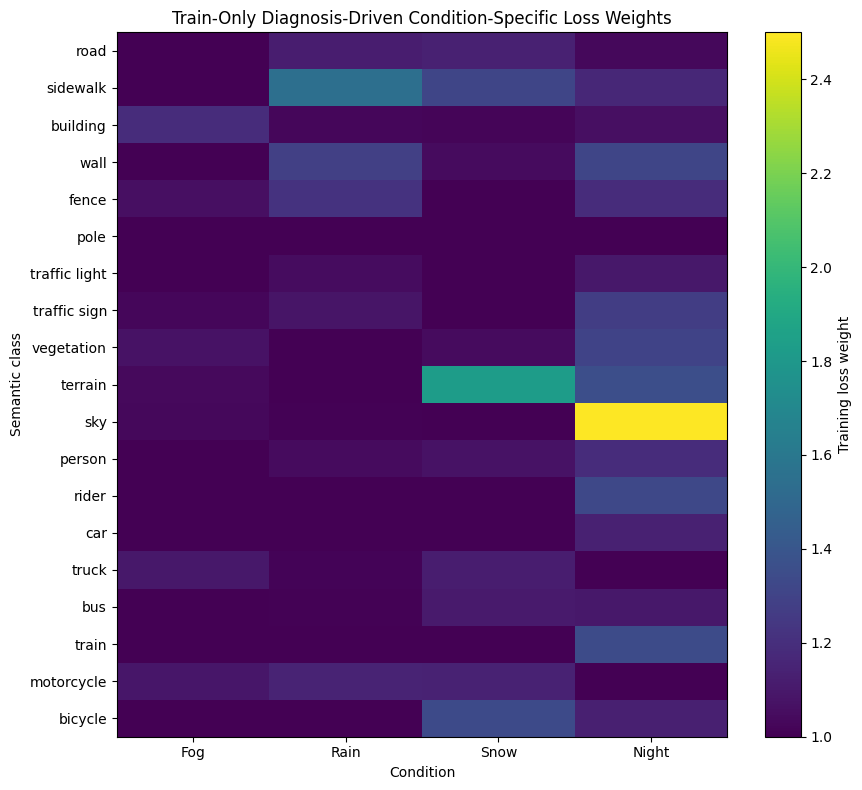

In [ ]:
# Cell 8 — Visualize the diagnosis-driven loss weights
pivot = (
    weight_df.pivot(index='class_name', columns='condition', values='loss_weight')
    .reindex(index=CLASS_NAMES, columns=CONDITIONS)
)

plt.figure(figsize=(9, 8))
plt.imshow(pivot.values, aspect='auto')
plt.colorbar(label='Training loss weight')
plt.xticks(range(len(CONDITIONS)), [c.title() for c in CONDITIONS])
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.title('Train-Only Diagnosis-Driven Condition-Specific Loss Weights')
plt.xlabel('Condition')
plt.ylabel('Semantic class')
plt.tight_layout()
plt.savefig(MOD_RESULTS_DIR / 'vulnerability_aware_loss_weights.png', dpi=250, bbox_inches='tight')
plt.show()

## Part C — Build the ACDC **train-only** segmentation dataset

Training uses adverse ACDC `train` images and their semantic GT + `invIds` masks.

- `invIds == 1` → label set to `255` (ignored by the loss)
- GT is resized to 512×512 with **nearest-neighbor** interpolation
- RGB images are prepared by the same SegFormer processor used in the baseline
- Official ACDC `val` images are not extracted or used here


In [ ]:
# Cell 9 — Copy archives locally (avoids Google Drive transport issues during repeated reads)
LOCAL_RGB_ZIP = Path('/content/rgb_anon.zip')
LOCAL_GT_ZIP = Path('/content/gt_trainval.zip')

for source, destination in [(ACDC_RGB_ZIP, LOCAL_RGB_ZIP), (ACDC_GT_ZIP, LOCAL_GT_ZIP)]:
    assert source.exists(), f'Missing archive: {source}'
    if not destination.exists():
        print('Copying', source.name, 'to local disk...')
        shutil.copy2(source, destination)
    else:
        print('Local archive already exists:', destination)

print('✓ Local archives ready.')

Copying rgb_anon.zip to local disk...
Copying gt_trainval.zip to local disk...
✓ Local archives ready.


In [ ]:
# Cell 10 — Discover all adverse ACDC TRAIN RGB/GT/invIds entries robustly

def scene_key_from_rgb(name):
    return Path(name).name.replace('_rgb_anon.png', '')

def scene_key_from_gt(name, suffix):
    return Path(name).name.replace(suffix, '')

with zipfile.ZipFile(LOCAL_RGB_ZIP, 'r') as z:
    rgb_names = [n for n in z.namelist() if n.endswith('_rgb_anon.png') and '__MACOSX' not in n]

with zipfile.ZipFile(LOCAL_GT_ZIP, 'r') as z:
    gt_names = [n for n in z.namelist() if n.endswith('.png') and '__MACOSX' not in n]

rgb_lookup, gt_lookup, inv_lookup = {}, {}, {}

for name in rgb_names:
    parts = name.split('/')
    for condition in CONDITIONS:
        if condition in parts and 'train' in parts and 'train_ref' not in parts:
            key = scene_key_from_rgb(name)
            rgb_lookup[(condition, key)] = name
            break

for name in gt_names:
    parts = name.split('/')
    condition = next((c for c in CONDITIONS if c in parts), None)
    if condition is None or 'train' not in parts or 'train_ref' in parts:
        continue

    if name.endswith('_gt_labelTrainIds.png'):
        key = scene_key_from_gt(name, '_gt_labelTrainIds.png')
        gt_lookup[(condition, key)] = name
    elif name.endswith('_gt_invIds.png'):
        key = scene_key_from_gt(name, '_gt_invIds.png')
        inv_lookup[(condition, key)] = name

train_rows = []
for (condition, key), rgb_path in rgb_lookup.items():
    if (condition, key) in gt_lookup and (condition, key) in inv_lookup:
        train_rows.append({
            'condition': condition,
            'scene_key': key,
            'rgb_member': rgb_path,
            'gt_member': gt_lookup[(condition, key)],
            'inv_member': inv_lookup[(condition, key)],
        })

train_manifest = pd.DataFrame(train_rows).sort_values(['condition','scene_key']).reset_index(drop=True)
print('ACDC train images found:', len(train_manifest))
display(train_manifest.groupby('condition').size().rename('images').to_frame())

# ACDC train is expected to contain 400 adverse images per condition = 1,600 total.
assert len(train_manifest) == 1600, f'Expected 1600 ACDC train images, found {len(train_manifest)}.'
train_manifest.to_csv(MOD_RESULTS_DIR / 'acdc_train_training_manifest.csv', index=False)
print('✓ ACDC train manifest verified.')

ACDC train images found: 1600


,images
condition,
fog,400
night,400
rain,400
snow,400


✓ ACDC train manifest verified.


In [ ]:
# Cell 11 — Extract only ACDC TRAIN RGB, semantic GT and invIds to fast local storage
LOCAL_TRAIN_ROOT = Path('/content/acdc_train_modification')
RGB_ROOT = LOCAL_TRAIN_ROOT / 'rgb'
GT_ROOT = LOCAL_TRAIN_ROOT / 'gt'
INV_ROOT = LOCAL_TRAIN_ROOT / 'inv'
for d in [RGB_ROOT, GT_ROOT, INV_ROOT]:
    d.mkdir(parents=True, exist_ok=True)


def safe_local_name(condition, key):
    return f'{condition}__{key}.png'

# Extract only if missing
with zipfile.ZipFile(LOCAL_RGB_ZIP, 'r') as z_rgb, zipfile.ZipFile(LOCAL_GT_ZIP, 'r') as z_gt:
    for i, row in train_manifest.iterrows():
        out_rgb = RGB_ROOT / safe_local_name(row.condition, row.scene_key)
        out_gt = GT_ROOT / safe_local_name(row.condition, row.scene_key)
        out_inv = INV_ROOT / safe_local_name(row.condition, row.scene_key)

        if not out_rgb.exists():
            with z_rgb.open(row.rgb_member) as src, open(out_rgb, 'wb') as dst:
                shutil.copyfileobj(src, dst)
        if not out_gt.exists():
            with z_gt.open(row.gt_member) as src, open(out_gt, 'wb') as dst:
                shutil.copyfileobj(src, dst)
        if not out_inv.exists():
            with z_gt.open(row.inv_member) as src, open(out_inv, 'wb') as dst:
                shutil.copyfileobj(src, dst)

        if (i + 1) % 200 == 0 or i + 1 == len(train_manifest):
            print(f'Extracted {i+1}/{len(train_manifest)}')

train_manifest['rgb_path'] = [str(RGB_ROOT / safe_local_name(r.condition, r.scene_key)) for r in train_manifest.itertuples()]
train_manifest['gt_path'] = [str(GT_ROOT / safe_local_name(r.condition, r.scene_key)) for r in train_manifest.itertuples()]
train_manifest['inv_path'] = [str(INV_ROOT / safe_local_name(r.condition, r.scene_key)) for r in train_manifest.itertuples()]

print('✓ Local training files ready.')

Extracted 200/1600
Extracted 400/1600
Extracted 600/1600
Extracted 800/1600
Extracted 1000/1600
Extracted 1200/1600
Extracted 1400/1600
Extracted 1600/1600
✓ Local training files ready.


In [ ]:
# Cell 12 — Processor and Dataset
processor = AutoImageProcessor.from_pretrained(BASE_CHECKPOINT)

class ACDCTrainDataset(Dataset):
    def __init__(self, dataframe, processor, image_size=512):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row['rgb_path']).convert('RGB')
        gt = Image.open(row['gt_path'])
        inv = Image.open(row['inv_path'])

        # Image preprocessing is controlled by the checkpoint processor.
        proc = self.processor(images=image, return_tensors='pt')
        pixel_values = proc['pixel_values'].squeeze(0)

        # Resize labels/mask to training resolution with nearest-neighbor only.
        gt = gt.resize((self.image_size, self.image_size), resample=Image.Resampling.NEAREST)
        inv = inv.resize((self.image_size, self.image_size), resample=Image.Resampling.NEAREST)

        labels = np.array(gt, dtype=np.int64)
        invalid = np.array(inv, dtype=np.uint8)

        valid_semantic = (labels >= 0) & (labels < NUM_CLASSES)
        valid = valid_semantic & (invalid == 0)
        labels = np.where(valid, labels, IGNORE_INDEX).astype(np.int64)

        return {
            'pixel_values': pixel_values,
            'labels': torch.from_numpy(labels),
            'condition_id': torch.tensor(CONDITION_TO_ID[row['condition']], dtype=torch.long),
            'condition': row['condition'],
            'scene_key': row['scene_key'],
        }

full_train_dataset = ACDCTrainDataset(train_manifest, processor)
print('Dataset size:', len(full_train_dataset))
sample = full_train_dataset[0]
print('pixel_values:', tuple(sample['pixel_values'].shape))
print('labels:', tuple(sample['labels'].shape))
print('condition:', sample['condition'])
print('valid label fraction:', float((sample['labels'] != IGNORE_INDEX).float().mean()))

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Dataset size: 1600
pixel_values: (3, 512, 512)
labels: (512, 512)
condition: fog
valid label fraction: 0.9651832580566406


In [ ]:
# Cell 13 — Create a 90/10 INTERNAL holdout from ACDC train (stratified by condition)
# This is NOT the official ACDC validation split.
train_indices, holdout_indices = [], []
rng = np.random.default_rng(SEED)

for condition in CONDITIONS:
    idx = train_manifest.index[train_manifest['condition'] == condition].to_numpy()
    rng.shuffle(idx)
    n_holdout = int(round(0.10 * len(idx)))
    holdout_indices.extend(idx[:n_holdout].tolist())
    train_indices.extend(idx[n_holdout:].tolist())

train_subset = Subset(full_train_dataset, train_indices)
holdout_subset = Subset(full_train_dataset, holdout_indices)

print('Optimization subset:', len(train_subset))
print('Internal holdout:', len(holdout_subset))
print('Official ACDC validation used here: NO')

for condition in CONDITIONS:
    n_tr = sum(train_manifest.iloc[i]['condition'] == condition for i in train_indices)
    n_ho = sum(train_manifest.iloc[i]['condition'] == condition for i in holdout_indices)
    print(f'{condition:5}: train={n_tr}, internal_holdout={n_ho}')

Optimization subset: 1440
Internal holdout: 160
Official ACDC validation used here: NO
fog  : train=360, internal_holdout=40
rain : train=360, internal_holdout=40
snow : train=360, internal_holdout=40
night: train=360, internal_holdout=40


## Part D — Modify SegFormer-B2

The base architecture remains SegFormer-B2. We add a lightweight **residual channel-attention refinement** immediately before the final 19-class classifier.

The attention block learns to reweight decoder feature channels, while the vulnerability-aware loss tells the model which class/condition errors deserve additional emphasis according to the train-only diagnosis.


In [ ]:
# Cell 14 — Define the lightweight residual channel-attention refinement module
class ResidualChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.gate = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid(),
        )
        self.refine = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        attention = self.gate(self.pool(x))
        refined = self.refine(x * attention)
        return x + refined


class VulnerabilityAwareClassifier(nn.Module):
    def __init__(self, in_channels, num_classes=19, reduction=8, dropout=0.1):
        super().__init__()
        self.attention = ResidualChannelAttention(in_channels, reduction=reduction)
        self.dropout = nn.Dropout2d(dropout)
        self.classifier = nn.Conv2d(in_channels, num_classes, kernel_size=1)

    def forward(self, x):
        x = self.attention(x)
        x = self.dropout(x)
        return self.classifier(x)

In [ ]:
# Cell 15 — Load baseline SegFormer-B2 and install the modified classifier
model = SegformerForSemanticSegmentation.from_pretrained(BASE_CHECKPOINT)

old_classifier = model.decode_head.classifier
in_channels = old_classifier.in_channels
print('Original classifier input channels:', in_channels)

model.decode_head.classifier = VulnerabilityAwareClassifier(
    in_channels=in_channels,
    num_classes=NUM_CLASSES,
    reduction=8,
    dropout=0.1,
)

# Freeze everything first.
for p in model.parameters():
    p.requires_grad = False

# Train the complete decoder (including the new attention/refinement head).
for p in model.decode_head.parameters():
    p.requires_grad = True

# IMPORTANT:
# In current Hugging Face Transformers, SegFormer exposes its four MiT encoder
# stages through model.segformer.stages. We intentionally unfreeze ONLY the
# final encoder stage so that high-level features can adapt slightly while
# earlier stages remain frozen.
if not hasattr(model.segformer, 'stages'):
    raise RuntimeError(
        "This Transformers version does not expose SegFormer stages as "
        "model.segformer.stages. Check the installed Transformers version "
        "before training."
    )

num_stages = len(model.segformer.stages)
assert num_stages > 0, "No SegFormer encoder stages were found."

last_encoder_stage = model.segformer.stages[-1]
for p in last_encoder_stage.parameters():
    p.requires_grad = True

# Verification: fail loudly if the last stage was not actually unfrozen.
last_stage_params = list(last_encoder_stage.parameters())
assert len(last_stage_params) > 0, "Last encoder stage contains no parameters."
assert all(p.requires_grad for p in last_stage_params), (
    "Last encoder stage was not fully unfrozen."
)

# Verify earlier encoder stages remain frozen.
earlier_stage_params = [
    p
    for stage in model.segformer.stages[:-1]
    for p in stage.parameters()
]
assert all(not p.requires_grad for p in earlier_stage_params), (
    "An earlier encoder stage was unexpectedly unfrozen."
)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
last_stage_trainable = sum(p.numel() for p in last_encoder_stage.parameters() if p.requires_grad)
decoder_trainable = sum(p.numel() for p in model.decode_head.parameters() if p.requires_grad)

print('SegFormer encoder stages found:', num_stages)
print(f'Decoder trainable parameters: {decoder_trainable:,}')
print(f'Last encoder stage trainable parameters: {last_stage_trainable:,}')
print(f'Total trainable parameters: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)')
print('Last encoder stage unfrozen: True')

# Helpful inspection of exactly what is trainable.
trainable_prefixes = sorted({
    name.split('.')[0] + '.' + name.split('.')[1]
    if '.' in name else name
    for name, p in model.named_parameters()
    if p.requires_grad
})
print('Trainable parameter groups:', trainable_prefixes[:20])


config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Original classifier input channels: 768
SegFormer encoder stages found: 4
Decoder trainable parameters: 8,623,219
Last encoder stage trainable parameters: 10,995,712
Total trainable parameters: 19,618,931 / 32,819,507 (59.78%)
Last encoder stage unfrozen: True
Trainable parameter groups: ['decode_head.batch_norm', 'decode_head.classifier', 'decode_head.linear_fuse', 'decode_head.linear_projections', 'segformer.stages']


In [ ]:
# Cell 16 — Condition-specific vulnerability-aware segmentation loss
weight_tensor = torch.tensor(condition_class_weights, dtype=torch.float32)


def vulnerability_aware_loss(logits, labels, condition_ids, condition_weights):
    # Match logits to the 512×512 training labels.
    logits = F.interpolate(
        logits,
        size=labels.shape[-2:],
        mode='bilinear',
        align_corners=False,
    )

    # Standard pixelwise CE first; ignore_index contributes zero.
    ce = F.cross_entropy(
        logits,
        labels,
        ignore_index=IGNORE_INDEX,
        reduction='none',
    )

    pixel_weights = torch.ones_like(ce)
    valid_mask = labels != IGNORE_INDEX

    for b in range(labels.shape[0]):
        valid = valid_mask[b]
        if valid.any():
            cls = labels[b][valid]
            pixel_weights[b][valid] = condition_weights[condition_ids[b], cls]

    weighted_sum = (ce * pixel_weights).sum()
    denom = pixel_weights[valid_mask].sum().clamp_min(1.0)
    return weighted_sum / denom

In [ ]:
# Cell 17 — DataLoaders and optimization settings
BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 2
EPOCHS = 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 3
NUM_WORKERS = 2

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

holdout_loader = DataLoader(
    holdout_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

DEVICE = torch.device('cuda')
model.to(DEVICE)
condition_weight_tensor = weight_tensor.to(DEVICE)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

USE_AMP = True
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
print('Device:', DEVICE)
print('GPU:', torch.cuda.get_device_name(0))
print('Mixed precision:', USE_AMP)
print('Effective batch size:', BATCH_SIZE * GRAD_ACCUM_STEPS)

Device: cuda
GPU: Tesla T4
Mixed precision: True
Effective batch size: 4


In [ ]:
# Cell 18 — Internal-holdout evaluation helper
@torch.no_grad()
def evaluate_internal(model, loader):
    model.eval()
    total_loss = 0.0
    n_batches = 0
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

    for batch in loader:
        pixel_values = batch['pixel_values'].to(DEVICE, non_blocking=True)
        labels = batch['labels'].to(DEVICE, non_blocking=True)
        condition_ids = batch['condition_id'].to(DEVICE, non_blocking=True)

        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits
        loss = vulnerability_aware_loss(
            logits, labels, condition_ids, condition_weight_tensor
        )
        total_loss += float(loss.item())
        n_batches += 1

        logits_up = F.interpolate(
            logits, size=labels.shape[-2:], mode='bilinear', align_corners=False
        )
        preds = logits_up.argmax(dim=1)

        for gt, pred in zip(labels.cpu().numpy(), preds.cpu().numpy()):
            valid = gt != IGNORE_INDEX
            gt_v = gt[valid]
            pred_v = pred[valid]
            bins = np.bincount(
                NUM_CLASSES * gt_v.astype(np.int64) + pred_v.astype(np.int64),
                minlength=NUM_CLASSES * NUM_CLASSES,
            )
            cm += bins.reshape(NUM_CLASSES, NUM_CLASSES)

    ious = iou_from_confusion(cm)
    miou = float(np.nanmean(ious))
    return total_loss / max(n_batches, 1), miou, ious

## Part E — Train the diagnosis-driven modified model

The best checkpoint is selected using the **internal 10% holdout from ACDC train**, never the official ACDC validation split.


In [ ]:
# Cell 19 — Training loop
history = []
best_miou = -np.inf
best_state = None
patience_left = PATIENCE

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    running_loss = 0.0
    step_count = 0

    for step, batch in enumerate(train_loader, start=1):
        pixel_values = batch['pixel_values'].to(DEVICE, non_blocking=True)
        labels = batch['labels'].to(DEVICE, non_blocking=True)
        condition_ids = batch['condition_id'].to(DEVICE, non_blocking=True)

        with torch.amp.autocast('cuda', enabled=USE_AMP):
            outputs = model(pixel_values=pixel_values)
            loss = vulnerability_aware_loss(
                outputs.logits,
                labels,
                condition_ids,
                condition_weight_tensor,
            )
            loss_for_backward = loss / GRAD_ACCUM_STEPS

        scaler.scale(loss_for_backward).backward()

        if step % GRAD_ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                max_norm=1.0,
            )
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += float(loss.item())
        step_count += 1

        if step % 100 == 0 or step == len(train_loader):
            print(
                f'Epoch {epoch}/{EPOCHS} | step {step}/{len(train_loader)} '
                f'| train loss {running_loss/step_count:.4f}'
            )

    train_loss = running_loss / max(step_count, 1)
    holdout_loss, holdout_miou, holdout_ious = evaluate_internal(model, holdout_loader)

    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'internal_holdout_loss': holdout_loss,
        'internal_holdout_miou': holdout_miou,
    }
    history.append(row)

    print(
        f'\nEpoch {epoch}: train_loss={train_loss:.4f} | '
        f'internal_holdout_loss={holdout_loss:.4f} | '
        f'internal_holdout_mIoU={holdout_miou:.4f}'
    )

    if holdout_miou > best_miou:
        best_miou = holdout_miou
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        patience_left = PATIENCE
        print('✓ New best internal-holdout checkpoint')
    else:
        patience_left -= 1
        print('No improvement. Patience left:', patience_left)
        if patience_left <= 0:
            print('Early stopping.')
            break

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv(TRAIN_LOG_DIR / 'training_history.csv', index=False)

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8 | step 100/720 | train loss 0.8185
Epoch 1/8 | step 200/720 | train loss 0.6081
Epoch 1/8 | step 300/720 | train loss 0.5136
Epoch 1/8 | step 400/720 | train loss 0.4642
Epoch 1/8 | step 500/720 | train loss 0.4338
Epoch 1/8 | step 600/720 | train loss 0.4061
Epoch 1/8 | step 700/720 | train loss 0.3862
Epoch 1/8 | step 720/720 | train loss 0.3838

Epoch 1: train_loss=0.3838 | internal_holdout_loss=0.2398 | internal_holdout_mIoU=0.5539
✓ New best internal-holdout checkpoint
Epoch 2/8 | step 100/720 | train loss 0.2543
Epoch 2/8 | step 200/720 | train loss 0.2491
Epoch 2/8 | step 300/720 | train loss 0.2392
Epoch 2/8 | step 400/720 | train loss 0.2371
Epoch 2/8 | step 500/720 | train loss 0.2336
Epoch 2/8 | step 600/720 | train loss 0.2322
Epoch 2/8 | step 700/720 | train loss 0.2285
Epoch 2/8 | step 720/720 | train loss 0.2285

Epoch 2: train_loss=0.2285 | internal_holdout_loss=0.2203 | internal_holdout_mIoU=0.6008
✓ New best internal-holdout checkpoint
Epoch 3/8 | step 100/7

,epoch,train_loss,internal_holdout_loss,internal_holdout_miou
0,1,0.383824,0.239763,0.553942
1,2,0.228545,0.220261,0.600787
2,3,0.194444,0.204210,0.617077
3,4,0.174023,0.194491,0.631749
4,5,0.157671,0.193712,0.629736
5,6,0.148625,0.189109,0.639039
6,7,0.138678,0.188739,0.645092
7,8,0.130432,0.190066,0.650530


In [ ]:
# Cell 20 — Restore and save the best modified model
assert best_state is not None, 'No best state was recorded.'
model.load_state_dict(best_state)
model.to('cpu')

# Save state dict. Notebook 10 will recreate the same custom head and load this file.
STATE_PATH = MODEL_OUT_DIR / 'model_state_dict.pt'
torch.save(model.state_dict(), STATE_PATH)

# Save processor + base config for reproducibility.
processor.save_pretrained(MODEL_OUT_DIR / 'processor')
model.config.save_pretrained(MODEL_OUT_DIR / 'config')

modification_config = {
    'base_checkpoint': BASE_CHECKPOINT,
    'num_classes': NUM_CLASSES,
    'image_size': 512,
    'attention_head': {
        'type': 'ResidualChannelAttention',
        'reduction': 8,
        'dropout': 0.1,
    },
    'trainable_parts': {
        'decode_head': True,
        'last_encoder_stage': True,
    },
    'loss': {
        'type': 'condition_specific_vulnerability_aware_cross_entropy',
        'support_full_pairs': SUPPORT_FULL,
        'max_extra_weight': MAX_EXTRA_WEIGHT,
        'weight_range': [1.0, 1.0 + MAX_EXTRA_WEIGHT],
        'weight_source': 'ACDC train_ref matched diagnosis only',
        'bootstrap_resamples': N_BOOT,
    },
    'training': {
        'acdc_split': 'train only',
        'official_acdc_validation_used': False,
        'internal_holdout_fraction': 0.10,
        'epochs_requested': EPOCHS,
        'best_internal_holdout_miou': float(best_miou),
        'learning_rate': LEARNING_RATE,
        'batch_size': BATCH_SIZE,
        'gradient_accumulation_steps': GRAD_ACCUM_STEPS,
        'seed': SEED,
    },
}

with open(MODEL_OUT_DIR / 'modification_config.json', 'w') as f:
    json.dump(modification_config, f, indent=2)

# Copy the exact diagnosis-driven weights beside the checkpoint.
weight_df.to_csv(MODEL_OUT_DIR / 'vulnerability_aware_loss_weights.csv', index=False)
np.save(MODEL_OUT_DIR / 'vulnerability_aware_loss_weights.npy', condition_class_weights)

print('Saved modified model state to:', STATE_PATH)
print('Best internal-holdout mIoU:', best_miou)


Saved modified model state to: /content/drive/MyDrive/CV_Project/models/vulnerability_aware_segformer_b2/model_state_dict.pt
Best internal-holdout mIoU: 0.6505298948718121


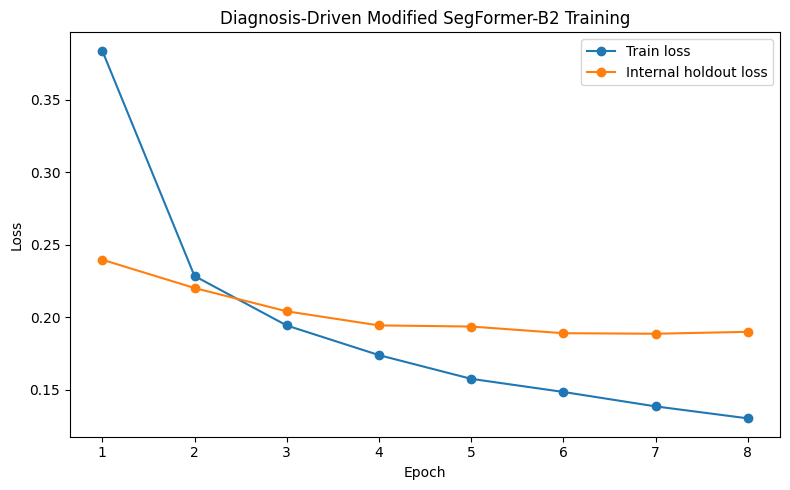

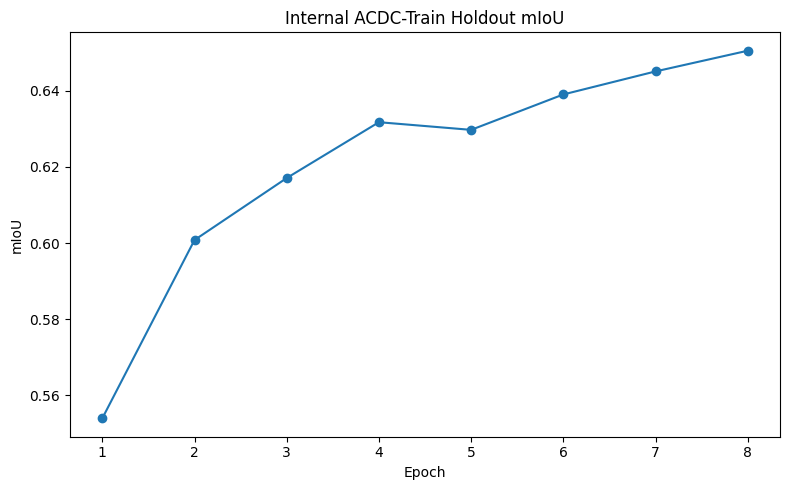

In [ ]:
# Cell 21 — Plot training history
history_df = pd.read_csv(TRAIN_LOG_DIR / 'training_history.csv')

plt.figure(figsize=(8, 5))
plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Train loss')
plt.plot(history_df['epoch'], history_df['internal_holdout_loss'], marker='o', label='Internal holdout loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Diagnosis-Driven Modified SegFormer-B2 Training')
plt.legend()
plt.tight_layout()
plt.savefig(TRAIN_LOG_DIR / 'training_loss_curve.png', dpi=250, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df['epoch'], history_df['internal_holdout_miou'], marker='o')
plt.xlabel('Epoch')
plt.ylabel('mIoU')
plt.title('Internal ACDC-Train Holdout mIoU')
plt.tight_layout()
plt.savefig(TRAIN_LOG_DIR / 'internal_holdout_miou_curve.png', dpi=250, bbox_inches='tight')
plt.show()